# ローカル SL / UL / DL 比較（再実装版）
元Notebookの復元ではありません。原本はoriginals/のZIPに保全しています。リポジトリの.venvカーネルで実行してください。

In [1]:
# STEP0: 共通関数の読込
from pathlib import Path
from datetime import datetime
import matplotlib.pyplot as plt
from diy_automl.workflow import run_csv
from diy_automl.plotting import plot_run
from diy_automl import render_excel_report


In [2]:
# STEP1: 入力と新規出力先
ROOT = Path.cwd() if (Path.cwd()/"data").exists() else Path.cwd().parent
CSV = ROOT / "data/reference/wine.csv"
OUTPUT = ROOT / "runs" / ("notebook-" + datetime.now().strftime("%Y%m%dT%H%M%S%f"))

In [3]:
# STEP2〜6: 共通の前処理・SL・UL・DL・集計
# DL分割seedと学習seedを独立に指定。test最高seedを選ばない。
run_csv(CSV, "target", OUTPUT, split_seed=42, training_seed=42)

2026-11-08 01:54:42.040372: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-08 01:54:42.086191: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


2026-11-08 01:54:43.514697: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


PosixPath('/workspace/DIY_AutoML/runs/notebook-20261108T015441287900')

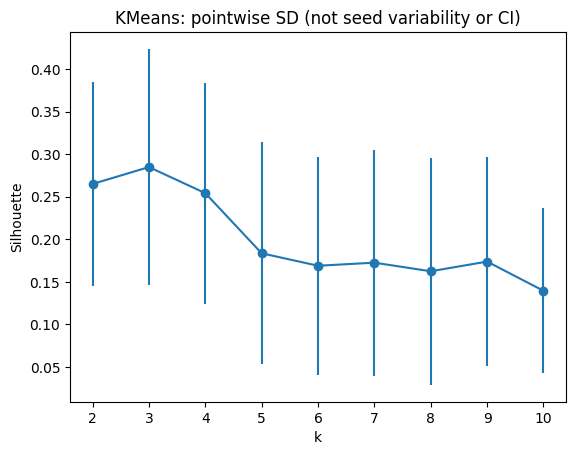

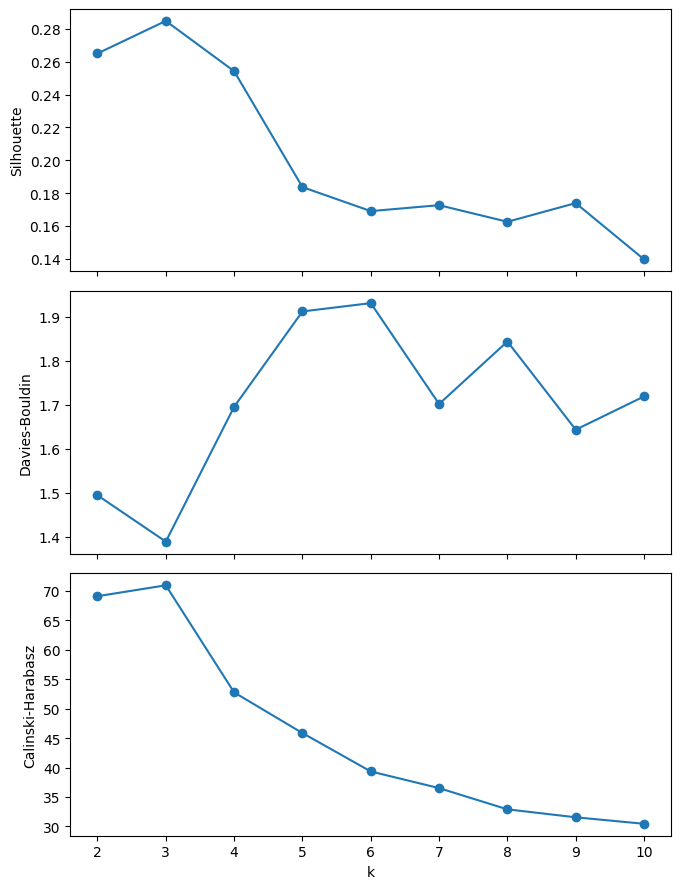

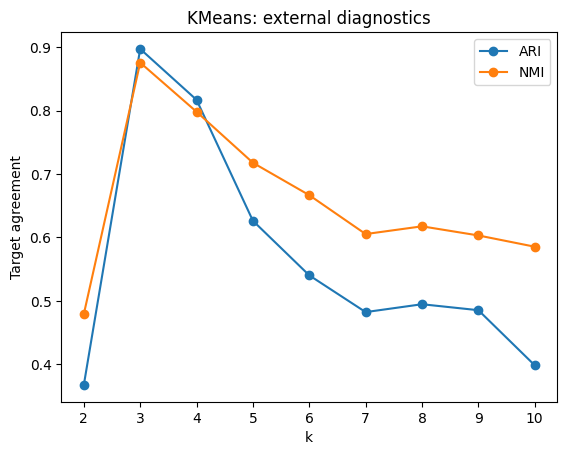

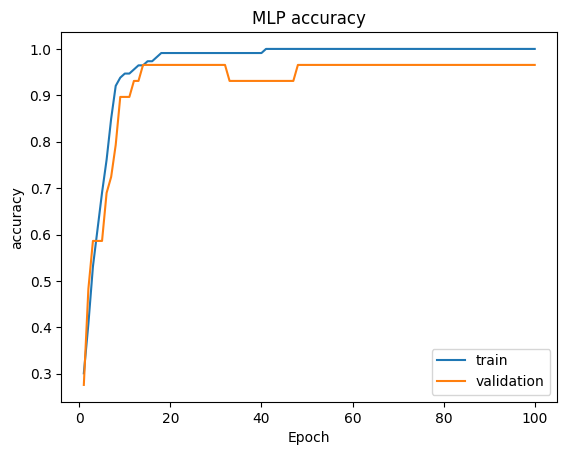

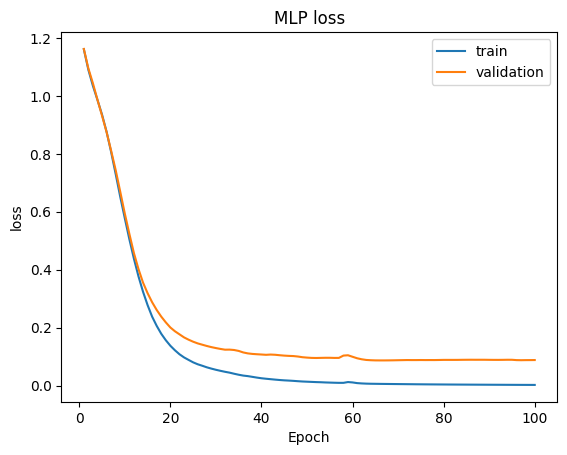

/workspace/DIY_AutoML/runs/notebook-20261108T015441287900


In [4]:
# STEP7: 保存済みの5シートと図5枚
# 図は外部PNG保存。Excel画像埋込は未実装。
figures = plot_run(OUTPUT)
plt.show()
print(OUTPUT)

In [5]:
# STEP7-追加: 保存済みの数値結果から、再学習せずに図付きExcelを作成
ILLUSTRATED = OUTPUT.with_name(OUTPUT.name + "-illustrated")
render_excel_report(OUTPUT, ILLUSTRATED)
print(ILLUSTRATED / "report_with_figures.xlsx")


/workspace/DIY_AutoML/runs/notebook-20261108T015441287900-illustrated/report_with_figures.xlsx
